# 02 · Data Understanding & EDA — *from scratch*

**Phase goal:** get to know the data *cold* — its shape, quality, the target's
distribution, and which columns actually move the price — before we model
anything. Self-contained: we load the raw file directly and clean it here.

Everything runs with just **pandas** and **matplotlib**.

In [1]:
# --- Imports (standard data-science stack only; nothing from the project) ---
import pandas as pd
import matplotlib.pyplot as plt

# The dataset ships as a gzip-compressed CSV. pandas detects the ".gz" suffix
# and decompresses it on the fly, so we can read it like a normal CSV.
DATA_PATH = "../data/raw/cars24-car-price-cleaned-new.csv.gz"

raw = pd.read_csv(DATA_PATH)
print("raw shape (rows, columns):", raw.shape)
raw.head()

raw shape (rows, columns): (19820, 17)


,selling_price,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,5,>5
0,1.20,120000,19.70,796.0,46.30,11.0,MARUTI,ALTO STD,1,0,0,0,0,1,1,1,0
1,5.50,20000,18.90,1197.0,82.00,7.0,HYUNDAI,GRAND I10 ASTA,1,0,0,0,0,1,1,1,0
2,2.15,60000,17.00,1197.0,80.00,13.0,HYUNDAI,I20 ASTA,1,0,0,0,0,1,1,1,0
3,2.26,37000,20.92,998.0,67.10,11.0,MARUTI,ALTO K10 2010-2014 VXI,1,0,0,0,0,1,1,1,0
4,5.70,30000,22.77,1498.0,98.59,8.0,FORD,ECOSPORT 2015-2021 1.5 TDCI TITANIUM BSIV,0,0,1,0,0,0,1,1,0


### What are the columns?
- **`selling_price`** — our target, in ₹ Lakhs.
- **Numeric:** `km_driven`, `mileage`, `engine`, `max_power`, `age`.
- **Text (high-cardinality):** `make`, `model`.
- **0/1 flags** (already one-hot encoded in the source): seller type
  (`Individual`, `Trustmark Dealer`), fuel (`Diesel`, `Electric`, `LPG`,
  `Petrol`), transmission (`Manual`), and seats (`5`, `>5`).

Let's check data quality — missing values and column types.

In [2]:
# Data quality: how many missing values per column, and what dtype is each?
print("Missing values per column:")
missing = raw.isna().sum()
print(missing[missing > 0] if missing.any() else "none")

print("\nColumn dtypes:")
print(raw.dtypes)

Missing values per column:
none

Column dtypes:
selling_price       float64
km_driven             int64
mileage             float64
engine              float64
max_power           float64
age                 float64
make                 object
model                object
Individual            int64
Trustmark Dealer      int64
Diesel                int64
Electric              int64
LPG                   int64
Petrol                int64
Manual                int64
5                     int64
>5                    int64
dtype: object


### Cleaning the data (written out step by step)
The raw file has two awkward column names (`5` and `>5` for the seat flags) and
a few unusable rows. We fix those with a small, explicit `clean` function so you
can see exactly what each step does — nothing is hidden in a library.

In [3]:
def clean(df):
    """Return a tidy copy of the raw data.

    Steps, in order:
      1. Rename the numeric-looking seat columns to valid identifiers.
      2. Drop rows with no price (we can't learn from a missing target).
      3. Drop rows with a non-positive price (data errors).
      4. Drop any remaining rows with missing values (keeps the demo simple).
      5. Normalise make/model text to UPPERCASE so 'Maruti' == ' maruti '.
    """
    df = df.rename(columns={"5": "Seats_5", ">5": "Seats_Above_5"})

    before = len(df)
    df = df.dropna(subset=["selling_price"])
    df = df[df["selling_price"] > 0]
    df = df.dropna()
    for col in ["make", "model"]:
        df[col] = df[col].astype(str).str.strip().str.upper()
    df = df.reset_index(drop=True)

    print(f"cleaned: kept {len(df):,} rows, dropped {before - len(df):,}")
    return df


df = clean(raw)
df.head(3)

cleaned: kept 19,820 rows, dropped 0


,selling_price,km_driven,mileage,engine,max_power,age,make,model,Individual,Trustmark Dealer,Diesel,Electric,LPG,Petrol,Manual,Seats_5,Seats_Above_5
0,1.20,120000,19.7,796.0,46.3,11.0,MARUTI,ALTO STD,1,0,0,0,0,1,1,1,0
1,5.50,20000,18.9,1197.0,82.0,7.0,HYUNDAI,GRAND I10 ASTA,1,0,0,0,0,1,1,1,0
2,2.15,60000,17.0,1197.0,80.0,13.0,HYUNDAI,I20 ASTA,1,0,0,0,0,1,1,1,0


### The target: `selling_price` (₹ Lakhs)
Resale prices are **right-skewed** — lots of cheap cars, a long thin tail of
expensive ones. This skew is exactly why we report **MAE** (a plain rupee error
that isn't dominated by a few luxury cars) alongside R².

count    19820.00
mean         6.59
std          4.85
min          0.30
25%          3.41
50%          5.20
75%          7.85
max         20.90
Name: selling_price, dtype: float64


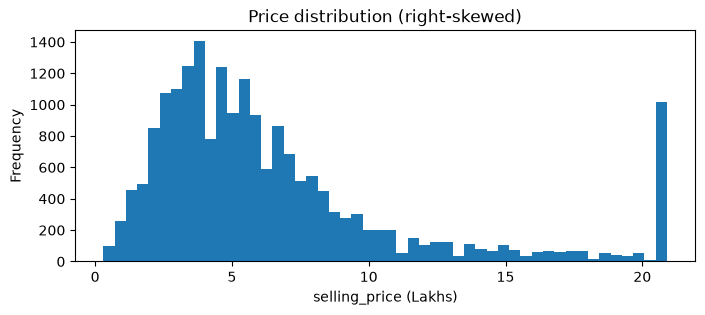

In [4]:
# Summary statistics of the price, then a histogram.
print(df["selling_price"].describe().round(2))

# Clip the long premium tail at 40 Lakhs so the shape stays readable.
ax = df["selling_price"].clip(upper=40).plot.hist(bins=50, figsize=(8, 3))
ax.set_xlabel("selling_price (Lakhs)")
ax.set_title("Price distribution (right-skewed)")
plt.show()

### The modelling challenge: `make` and `model` have *huge* cardinality
`make` has dozens of values, but `model` has **thousands**. If we naively
one-hot encoded `model`, we'd add thousands of columns — an enormous, slow,
mostly-empty matrix. Notebook 04 solves this with **target encoding**.

In [5]:
print("distinct makes :", df["make"].nunique())
print("distinct models:", df["model"].nunique())

# Which brands command the highest median price?
(df.groupby("make")["selling_price"]
   .median()
   .sort_values(ascending=False)
   .head(8))

distinct makes : 41
distinct models: 3233


make
LEXUS            20.9025
JAGUAR           20.9025
BENTLEY          20.9025
BMW              20.9025
ROLLS-ROYCE      20.9025
PORSCHE          20.9025
MERCEDES-BENZ    20.9025
FERRARI          20.9025
Name: selling_price, dtype: float64

In [6]:
# Which NUMERIC columns correlate most with price? (quick signal check)
numeric_cols = ["km_driven", "mileage", "engine", "max_power", "age"]
corr_with_price = (df[numeric_cols + ["selling_price"]]
                   .corr()["selling_price"]
                   .sort_values(ascending=False))
corr_with_price

selling_price    1.000000
max_power        0.770390
engine           0.652296
km_driven       -0.100739
mileage         -0.314927
age             -0.390667
Name: selling_price, dtype: float64

### Findings that shape the rest of the project
- **High cardinality:** thousands of distinct `model` values → we will
  **target-encode** `make`/`model` (nb 04), not one-hot them.
- **Skewed target:** always report **MAE in ₹**, not just R².
- **`max_power` and `engine` correlate strongly with price** → these are
  important features and must be filled sensibly at serve time, never dropped.
- **`age` correlates *negatively*** → older cars are cheaper, as expected. A good
  sanity check that the data behaves the way domain intuition says it should.